In [20]:
import csv

tickets = [
    (1, 'Amy', 'Server down in the main office, nobody can work'),
    (2, 'Ben', 'Printer on floor 2 is not printing'),
    (3, 'Cara', 'Cannot login to my email account'),
    (4, 'Dan', 'Wifi is slow in the meeting room'),
    (5, 'Eva', 'Need a password reset for the booking system'),
    (6, 'Finn', 'CCTV camera offline at the front entrance'),
    (7, 'Gina', 'Projector in room 3 shows no signal'),
    (8, 'Hugo', 'Please install new software on my laptop'),
    (9, 'Ivy', 'No network in the warehouse'),
    (10, 'Jack', 'Monitor flickering on my desk'),
    (11, 'Kim', 'How do I book a meeting room?'),
    (12, 'Leo', 'Email is very slow this morning'),
]
with open('tickets.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['id', 'name', 'description'])
    writer.writerows(tickets)
print('Created tickets.csv with', len(tickets), 'tickets')

Created tickets.csv with 12 tickets


In [21]:
CATEGORIES = {
    'Network': ['wifi', 'network', 'internet', 'server'],
    'Hardware': ['printer', 'monitor', 'projector', 'cctv', 'laptop'],
    'Account': ['login', 'password', 'email'],
}
HIGH_WORDS = ['server down', 'no network', 'offline', 'cannot login']
MEDIUM_WORDS = ['slow', 'not printing', 'no signal', 'password reset']

def triage(description):
    text = description.lower()
    category = 'General'
    for name, words in CATEGORIES.items():
        if any(word in text for word in words):
            category = name
            break
    priority = 'Low'
    if any(word in text for word in HIGH_WORDS):
        priority = 'High'
    elif any(word in text for word in MEDIUM_WORDS):
        priority = 'Medium'
    return category, priority

In [22]:
order = {'High': 0, 'Medium': 1, 'Low': 2}
results = []
with open('tickets.csv') as f:
    for row in csv.DictReader(f):
        category, priority = triage(row['description'])
        results.append([row['id'], row['name'], row['description'], category, priority])
results.sort(key=lambda r: order[r[4]])

with open('tickets_triaged.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['id', 'name', 'description', 'category', 'priority'])
    writer.writerows(results)

counts = {}
for r in results:
    counts[r[4]] = counts.get(r[4], 0) + 1
print('Triaged', len(results), 'tickets')
for p in ['High', 'Medium', 'Low']:
    print(p, ':', counts.get(p, 0))
print('First ticket to handle:', results[0][2])

Triaged 12 tickets
High : 4
Medium : 5
Low : 3
First ticket to handle: Server down in the main office, nobody can work


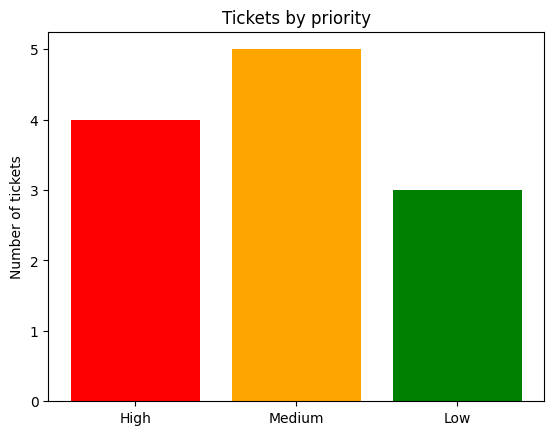

In [23]:
import matplotlib.pyplot as plt

labels = ['High', 'Medium', 'Low']
plt.bar(labels, [counts.get(p, 0) for p in labels], color=['red', 'orange', 'green'])
plt.title('Tickets by priority')
plt.ylabel('Number of tickets')
plt.show()

In [24]:
assert triage('Server down in the main office') == ('Network', 'High')
assert triage('Printer is not printing') == ('Hardware', 'Medium')
assert triage('Cannot login to my email account') == ('Account', 'High')
assert triage('Wifi is slow') == ('Network', 'Medium')
assert triage('How do I book a meeting room?') == ('General', 'Low')
print('All tests passed')

All tests passed
